# Solución del ejercicio 4: parte computacional

*El enunciado está en `ejercicios_3_y_4_transcripcion.md` y la parte analítica en `soluciones_parcial.pdf`.*

De la parte analítica usamos la regla de actualización con $\alpha=1$,
$$
q_i^{(t+1)}=\sum_{\mu=1}^{P}x_{\mu i}\,p_\mu\big(q^{(t)}\big),
\qquad
p_\mu(q)=\operatorname{softmax}\big(\beta Xq\big)_\mu=\frac{e^{\beta m_\mu(q)}}{\sum_\nu e^{\beta m_\nu(q)}},
\qquad
m_\mu(q)=\sum_{j}x_{\mu j}q_j,
$$
y el análisis de $\beta$: para $\beta$ pequeño la red tiende al promedio de los patrones, y para $\beta$ grande recupera en un solo paso el patrón de mayor solapamiento con el estado.

La implementación está en el paquete `memoria_asociativa`:

| Módulo | Contenido |
|---|---|
| `patrones.py` | `BancoPatrones`: letras J y H de $8\times8$ píxeles y la matriz $X$ de $2\times64$. |
| `red.py` | `RedMemoriaAsociativa`: energía, gradiente y `recuperar`, que itera la regla hasta que $\|q^{(t+1)}-q^{(t)}\|_\infty<10^{-10}$ o hasta un número máximo de iteraciones. |
| `experimentos.py` | `perturbar`, `barrido_ruido`, `barrido_beta` y `TeoriaDosPatrones` (reducción de la sección 1). |
| `graficos.py` | Figuras. |

El softmax y el log-sum-exp se calculan restando el máximo de $\beta m_\mu$, para que $e^{\beta m_\mu}$ no desborde con $\beta$ grande. Según la ayuda, el patrón binario es $\operatorname{sign}(q_i)$, con la convención $\operatorname{sign}(0)=+1$, y la calidad de la recuperación es el porcentaje de píxeles que coinciden con el original.

X: (2, 64)
X X^T =
 [[ 64. -20.]
 [-20.  64.]]
Distancia de Hamming d(J, H) = 42   ->   beta_c = 1/d = 0.02381


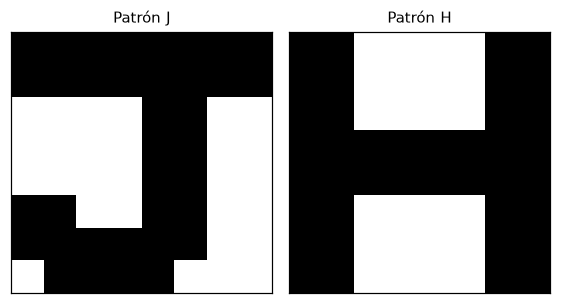

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from memoria_asociativa import (BancoPatrones, RedMemoriaAsociativa, TeoriaDosPatrones,
                                perturbar, barrido_ruido, barrido_beta, precision)
from memoria_asociativa import graficos

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

banco = BancoPatrones.letras("JH")
X = banco.X
teoria = TeoriaDosPatrones(banco, objetivo="J", otro="H")
x_J = banco["J"].vector

print("X:", X.shape)
print("X X^T =\n", banco.solapamientos())
print(f"Distancia de Hamming d(J, H) = {teoria.d}   ->   beta_c = 1/d = {teoria.beta_critico:.5f}")
graficos.mostrar_patrones(banco)
plt.show()

### 1. Dinámica con dos patrones

Ahora, con $P=2$ la regla con $\alpha=1$ se puede resolver de forma exacta, lo cual nos permite interpretar los experimentos. Sean $x_1=x_J$, $x_2=x_H$, $d$ su distancia de Hamming ($d=42$) y $c=x_1\cdot x_2=N-2d=-20$. Para dos patrones, el softmax queda
$$
u\equiv p_1-p_2=\tanh\left[\frac\beta2(m_1-m_2)\right],
$$
y entonces, para $t\ge1$,
$$
q^{(t)}=p_1x_1+p_2x_2=\frac{1+u_t}{2}x_1+\frac{1-u_t}{2}x_2.
$$
Ahora, como $x_1-x_2$ sólo es distinto de cero en los $d$ píxeles donde los patrones difieren, donde vale $2x_{1i}$, tenemos $m_1-m_2=(x_1-x_2)\cdot q^{(t)}=2d\,u_t$
$$
\Rightarrow\
\boxed{u_{t+1}=\tanh(\beta d\,u_t),\qquad u_1=\tanh\big(\beta(d-2k)\big)}
$$
donde $k$ es el número de píxeles invertidos de $q^{(0)}$ que caen en esos $d$ píxeles.

Así, como $\tanh$ es impar, $\operatorname{sign}(u_t)=\operatorname{sign}(d-2k)$ para todo $t\ge1$: la red converge a J si $k<d/2$, a H si $k>d/2$, y queda en la mezcla $u=0$ si $k=d/2$. Al invertir $n$ píxeles al azar, $k\sim\text{Hipergeométrica}(N,d,n)$.

Por su parte, los puntos fijos cumplen $u^*=\tanh(\beta d\,u^*)$. Si $\beta d\le1$, el único es $u^*=0$, es decir, la mezcla $\frac12(x_J+x_H)$. Si $\beta d>1$, $u=0$ se vuelve inestable y aparecen $\pm u^*\neq0$, de modo que la red recupera un patrón. El cambio ocurre en
$$
\boxed{\beta_c=\frac1d\approx0.0238}
$$

Por último, cerca de $u^*$ el error se reduce en un factor $\lambda=\beta d(1-u^{*2})$ por iteración. Como $E$ es estacionaria en $q^*$, la brecha $E(q^{(t)})-E(q^*)$ es cuadrática en $u_t-u^*$ y se reduce en un factor $\lambda^2$.

### (a) Patrón original, perturbado y estado final

Seleccionamos la J, invertimos al azar el $30\%$ de sus píxeles y aplicamos la regla con $\alpha=1$ y $\beta=0.1$ ($\beta d=4.2>1$), con un máximo de $1000$ iteraciones.

Píxeles invertidos: 19 de 64; k = 10 de ellos caen en los d = 42 píxeles distintos


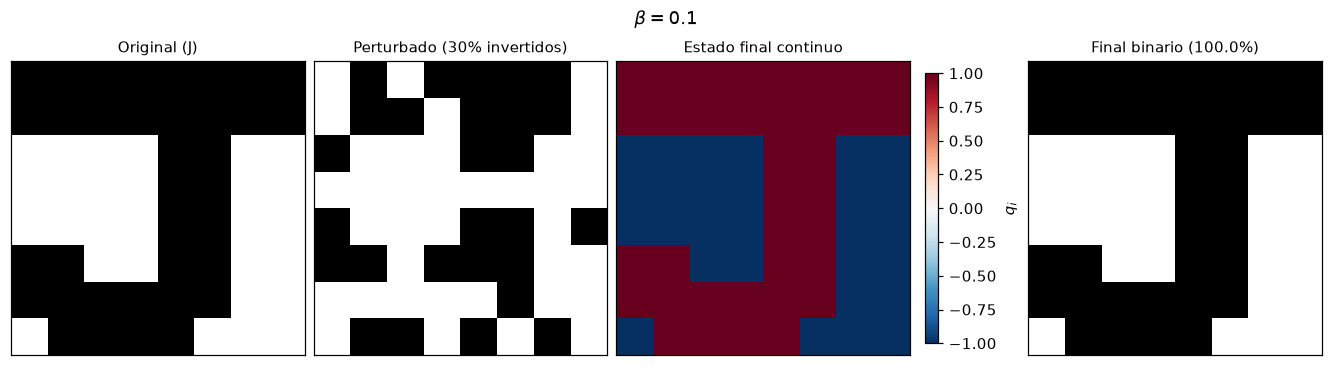

6 iteraciones, convergió = True, precisión binaria = 100.0%
|q_i| final en los píxeles comunes: [1.], en los distintos: [0.999549];  u* teórico = 0.999549


In [2]:
rng = np.random.default_rng(7)
q0 = perturbar(x_J, 0.30, rng)
distintos = banco.pixeles_distintos("J", "H")
k = int(np.sum(q0[distintos] != x_J[distintos]))
print(f"Píxeles invertidos: {np.sum(q0 != x_J)} de 64; k = {k} de ellos caen en los d = {teoria.d} píxeles distintos")

tray = RedMemoriaAsociativa(X, 0.1).recuperar(q0, max_iter=1000)
graficos.comparar_recuperacion(banco, "J", tray, titulo=r"$\beta=0.1$")
plt.show()
print(f"{tray.n_iter} iteraciones, convergió = {tray.convergio}, precisión binaria = {precision(tray.final, x_J):.1%}")
print(f"|q_i| final en los píxeles comunes: {np.unique(np.round(np.abs(tray.final[~distintos]), 6))}, "
      f"en los distintos: {np.unique(np.round(np.abs(tray.final[distintos]), 6))};  u* teórico = {teoria.punto_fijo(0.1):.6f}")

**Análisis.** Como $k=10<d/2=21$, la red converge a la J en $6$ iteraciones y recupera el $100\%$ de los píxeles. Ahora, el estado continuo final vale exactamente $\pm1$ en los $22$ píxeles comunes a J y H, y $\pm u^*=\pm0.9995$ en los $42$ píxeles que los distinguen, como se predijo en la sección 1. Así, al binarizarlo por el signo se obtiene la J. Es decir, el ruido desaparece en la primera iteración, porque $q^{(1)}$ ya es una combinación de $x_J$ y $x_H$.

### (b) Recuperación en función del porcentaje de píxeles perturbados

Ahora, para cada porcentaje alcanzable, $f=n/64$ con $n=0,1,\dots,64$ (pasos de $1.5625\%$), generamos $300$ perturbaciones aleatorias de la J y aplicamos la regla con $\beta=0.1$. Medimos la precisión binaria de la ayuda y el estado al que converge la red.

Las bandas son intervalos de confianza del $95\%$ de la media, $\pm1.96\,s/\sqrt{300}$. No usamos $\pm s$ porque la precisión de cada perturbación es bimodal ($100\%$ o $34.4\%$), de modo que $s$ mide esa dispersión y no la incertidumbre de la media. Las líneas son la predicción de la sección 1, evaluada en los mismos $n$.

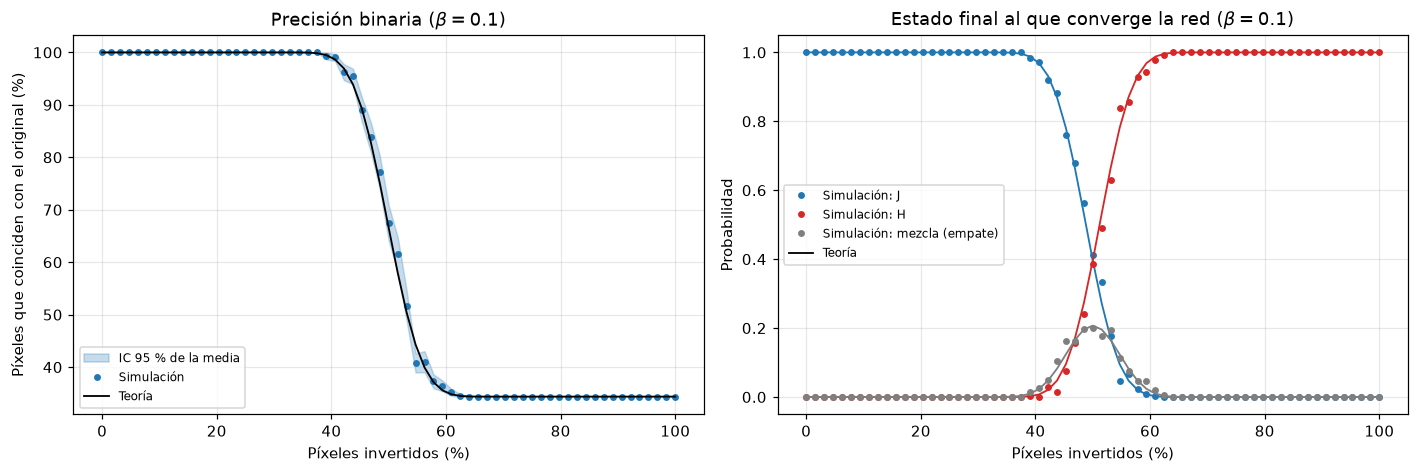

  n      % |   precisión (%) | teoría (%) |  P(J)  P(H) empate
  0   0.00 |  100.00 ±  0.00 |     100.00 |  1.00  0.00   0.00
 16  25.00 |  100.00 ±  0.00 |     100.00 |  1.00  0.00   0.00
 24  37.50 |  100.00 ±  0.00 |      99.85 |  1.00  0.00   0.00
 26  40.62 |   99.04 ±  0.66 |      98.66 |  0.97  0.00   0.03
 28  43.75 |   95.41 ±  1.48 |      93.94 |  0.88  0.01   0.10
 30  46.88 |   83.85 ±  2.83 |      82.92 |  0.68  0.16   0.16
 32  50.00 |   67.44 ±  3.33 |      66.54 |  0.41  0.39   0.20
 34  53.12 |   51.71 ±  2.85 |      50.42 |  0.18  0.63   0.19
 36  56.25 |   41.03 ±  2.00 |      39.93 |  0.07  0.86   0.08
 38  59.38 |   36.42 ±  1.01 |      35.57 |  0.01  0.94   0.05
 40  62.50 |   34.57 ±  0.27 |      34.51 |  0.00  0.99   0.01
 48  75.00 |   34.38 ±  0.00 |      34.38 |  0.00  1.00   0.00
 64 100.00 |   34.38 ±  0.00 |      34.38 |  0.00  1.00   0.00


In [3]:
fracciones = np.arange(banco.N + 1) / banco.N      # n = 0, 1, ..., 64 píxeles invertidos
res = barrido_ruido(RedMemoriaAsociativa(X, 0.1), banco, "J", fracciones, n_repeticiones=300,
                    semilla=2024, max_iter=2000)
graficos.curva_recuperacion(res, teoria)
plt.show()

ic = res.intervalo_media(res.precision)
print(f"{'n':>3} {'%':>6} | {'precisión (%)':>15} | {'teoría (%)':>10} | {'P(J)':>5} {'P(H)':>5} {'empate':>6}")
for i in (0, 16, 24, 26, 28, 30, 32, 34, 36, 38, 40, 48, 64):
    f = fracciones[i]
    print(f"{i:3d} {100 * f:6.2f} | {100 * res.precision_media[i]:7.2f} ± {100 * ic[i]:5.2f} | "
          f"{100 * teoria.precision_esperada(f):10.2f} | {res.tasa(0)[i]:5.2f} {res.tasa(1)[i]:5.2f} {res.tasa(-1)[i]:6.2f}")

**Análisis.**

Lo primero que vemos es que, hasta $n=24$ píxeles invertidos ($37.5\%$), las $300$ perturbaciones se corrigen al $100\%$. Entre $n\approx25$ y $n\approx40$ ($39\%$–$62\%$), la precisión media cae en forma de sigmoide de $100\%$ a $34.4\%$, y cada perturbación termina en uno de tres estados: la J, la H o la mezcla del empate exacto $k=21$, que en $n=32$ ocurre en el $20\%$ de los casos. Esto es porque, en promedio, $k=f\,d$ y el umbral es $k=d/2$, de modo que la transición está centrada en $50\%$. Su ancho, de unos $10$ píxeles, es el de la fluctuación hipergeométrica de $k$ ($\sigma_k\approx1.9$ en $n=32$).

Por su parte, para $n\ge41$ ($64\%$) la red recupera perfectamente la H, y por eso la precisión se estabiliza en $34.4\%=22/64$, la fracción de píxeles en que la H coincide con la J. Incluso con el $100\%$ de los píxeles invertidos, $q^{(0)}=-x_J$, la red converge a la H y no a $-x_J$, pues $E(q)$ no es simétrica bajo $q\to-q$ y los anti-patrones no son atractores.

Por último, las curvas teóricas, sin ningún parámetro ajustable, pasan por las bandas de confianza de la precisión y de las tres probabilidades. Es decir, con dos patrones la calidad de la recuperación depende sólo de cuántas inversiones caen en los $42$ píxeles que distinguen J de H.

### (c) Influencia de $\beta$ en la energía y en los estados finales

Ahora, partimos del mismo estado inicial (J con $30\%$ de píxeles invertidos) y variamos $\beta$ entre $0.002$ y $10$, a ambos lados de $\beta_c=1/42\approx0.0238$. Graficamos la brecha de energía $E(q^{(t)})-E(q^*)$ hasta el piso de redondeo de $E$ ($\sim50\,\varepsilon|E|$), y el peso $p_J^{(t)}$ que el softmax asigna a la J.

   beta  beta*d |  iter     E final |    u final u* teórico | prec. bin. | rho medido  lambda^2
  0.002    0.08 |    10   -357.5736 |  9.156e-12  0.000e+00 |    100.0% |     0.0071    0.0071
  0.010    0.42 |    27    -80.3147 |  3.456e-11  0.000e+00 |    100.0% |     0.1764    0.1764
  0.020    0.84 |   118    -45.6574 |  5.064e-10  0.000e+00 |    100.0% |     0.7056    0.7056
  0.030    1.26 |    44    -35.3852 |  7.195e-01  7.195e-01 |    100.0% |     0.3695    0.3694
  0.050    2.10 |    13    -32.3187 |  9.660e-01  9.660e-01 |    100.0% |     0.0197    0.0197
  0.100    4.20 |     6    -32.0023 |  9.995e-01  9.995e-01 |    100.0% |        nan    0.0000
  1.000   42.00 |     2    -32.0000 |  1.000e+00  1.000e+00 |    100.0% |        nan    0.0000
 10.000  420.00 |     2    -32.0000 |  1.000e+00  1.000e+00 |    100.0% |        nan    0.0000


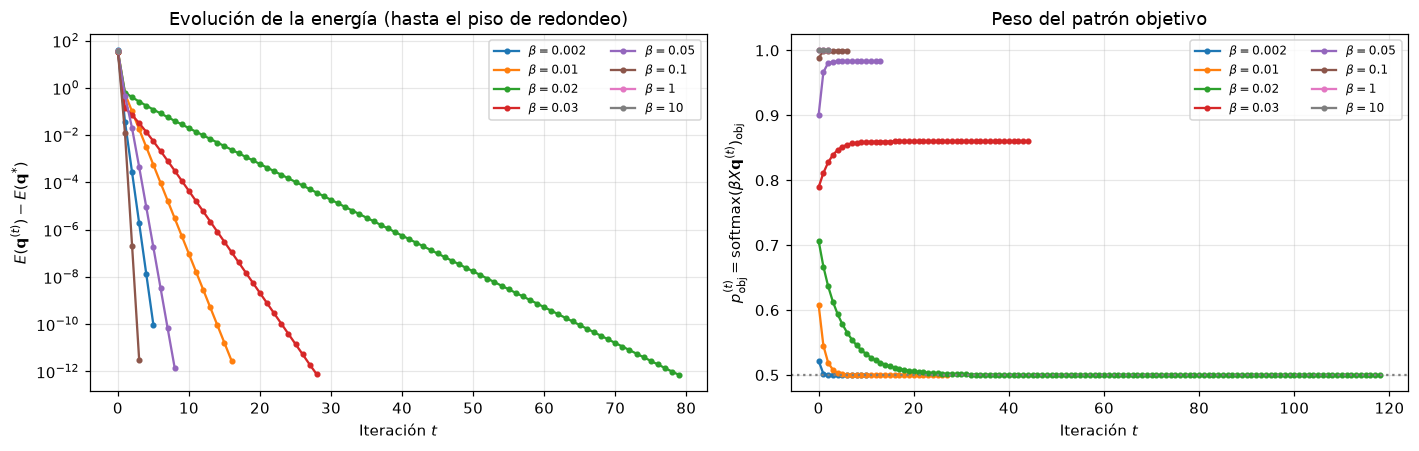

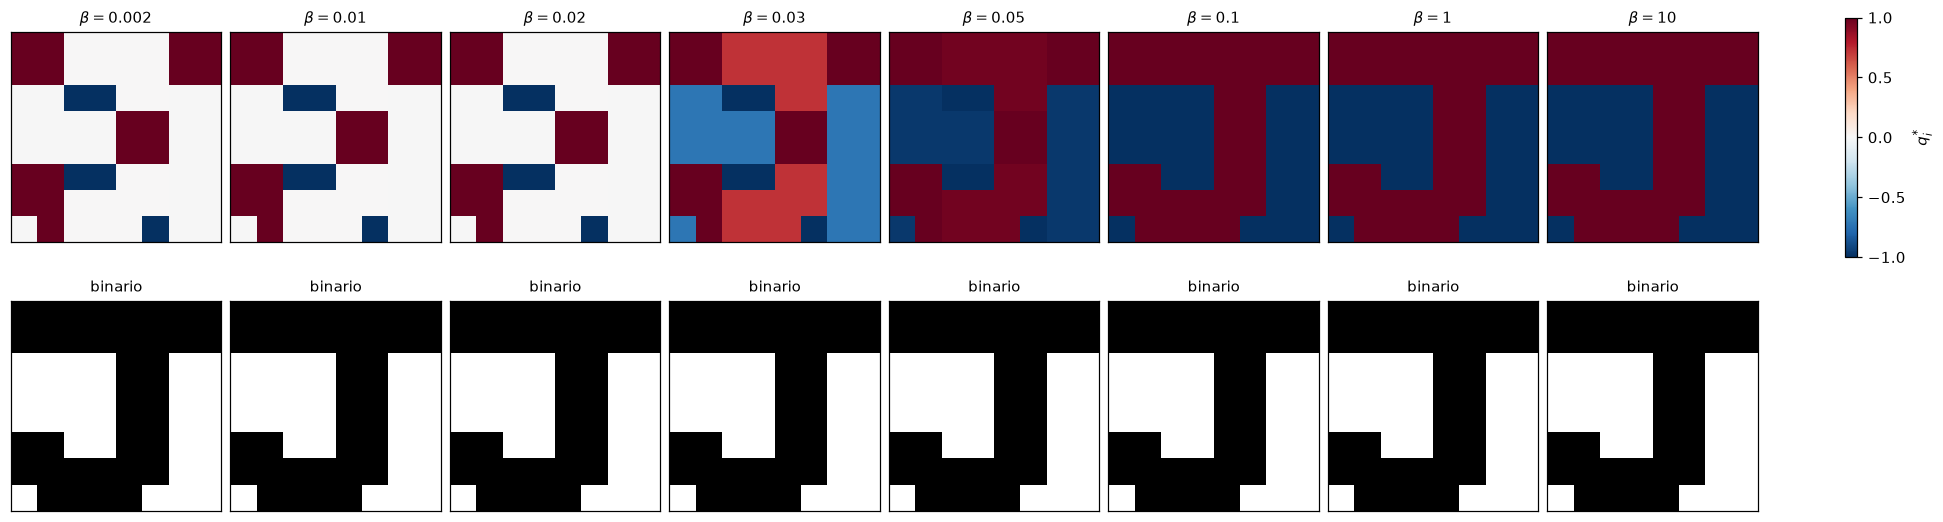

In [4]:
rng = np.random.default_rng(3)
q0 = perturbar(x_J, 0.30, rng)
u0 = teoria.u_de_estado(q0)
betas_c = [0.002, 0.01, 0.02, 0.03, 0.05, 0.1, 1.0, 10.0]
trayectorias = barrido_beta(X, q0, betas_c, max_iter=5000)

print(f"{'beta':>7} {'beta*d':>7} | {'iter':>5} {'E final':>11} | {'u final':>10} {'u* teórico':>10} | "
      f"{'prec. bin.':>9} | {'rho medido':>10} {'lambda^2':>9}")
for b, tr in trayectorias.items():
    print(f"{b:7.3f} {b * teoria.d:7.2f} | {tr.n_iter:5d} {tr.energias[-1]:11.4f} | "
          f"{teoria.u_de_estado(tr.final):10.3e} {teoria.punto_fijo(b):10.3e} | {precision(tr.final, x_J):9.1%} | "
          f"{tr.cociente_energia():10.4f} {teoria.tasa_convergencia(b) ** 2:9.4f}")

graficos.evolucion_energia(trayectorias, objetivo_idx=banco.indice("J"))
graficos.estados_finales(banco, trayectorias)
plt.show()

Para ver cómo dependen los estados finales de $\beta$, barremos $\beta$ finamente y comparamos el valor final de $u$ con $u^*=\tanh(\beta d\,u^*)$, y el número de iteraciones con el del mapa reducido $u_{t+1}=\tanh(\beta d\,u_t)$.

¿Iteraciones de la red = iteraciones del mapa reducido? True


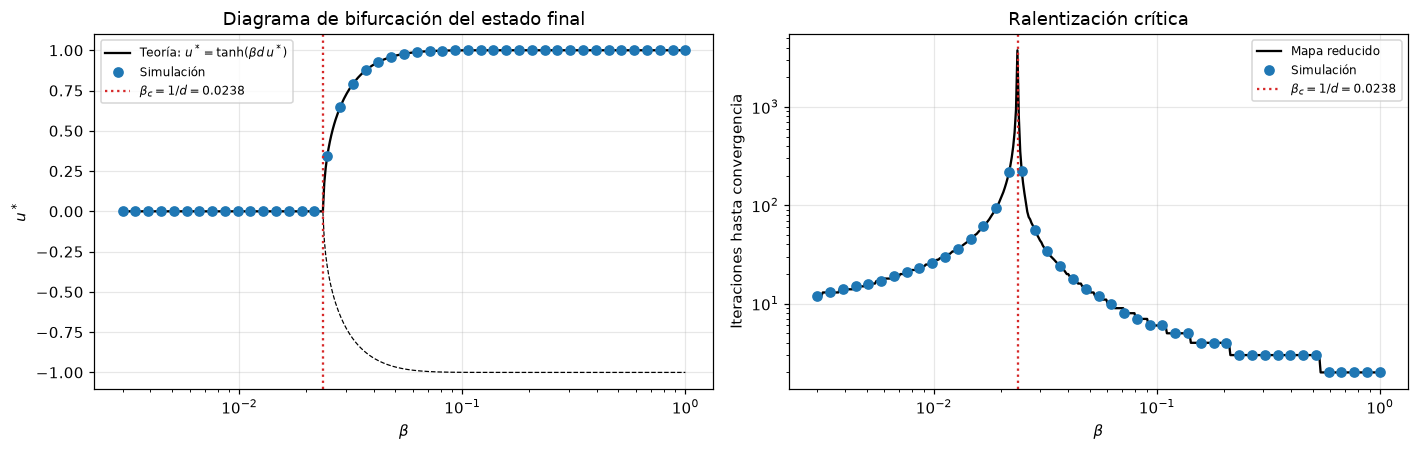

In [5]:
betas_f = np.geomspace(0.003, 1.0, 45)
MAX_ITER = 20000
tray_f = barrido_beta(X, q0, betas_f, max_iter=MAX_ITER)
u_sim = [teoria.u_de_estado(t.final) for t in tray_f.values()]
it_sim = [t.n_iter for t in tray_f.values()]
it_teo = [teoria.iteraciones_teoricas(b, u0, max_iter=MAX_ITER) for b in betas_f]
print("¿Iteraciones de la red = iteraciones del mapa reducido?", it_sim == it_teo)

graficos.bifurcacion(teoria, betas_f, u_sim, it_sim, u0, max_iter=MAX_ITER)
plt.show()

**Análisis de la influencia de $\beta$.**

Ahora, en todos los casos $E(q^{(t)})$ decrece de forma monótona. Los valores absolutos de $E$ no se pueden comparar entre distintos $\beta$, porque incluyen el término $-\frac1\beta\ln P$, y por eso graficamos la brecha. Con el eje de iteraciones lineal, cada curva es una recta, es decir, la convergencia es geométrica, y su cociente por iteración coincide con $\lambda^2=[\beta d(1-u^{*2})]^2$ en cuatro cifras (tabla). Entonces, la convergencia es más lenta cuanto más cerca está $\beta$ de $\beta_c$: la brecha tarda unas $80$ iteraciones en llegar al redondeo con $\beta=0.02$ ($\lambda^2=0.71$) y unas $30$ con $\beta=0.03$ ($\lambda^2=0.37$). Para $\beta\ge1$, $\lambda\approx0$ y la red converge en un solo paso: $p_J$ salta de inmediato a $1$, que es el régimen de $\beta$ grande de la parte analítica.

Por su parte, para $\beta>\beta_c$ el estado continuo final es la J, con contraste $\pm u^*$ en los píxeles que la distinguen de la H, y $u^*\to1$ al aumentar $\beta$. Para $\beta<\beta_c$, en cambio, $p_J\to\frac12$ y el estado final es la mezcla $\frac12(x_J+x_H)$, que es nula en esos píxeles: todos los patrones contribuyen por igual y la red olvida de cuál partió, que es el régimen de $\beta$ pequeño. El patrón binario es la J en todos los casos, porque $u_t$ conserva su signo, pero para $\beta<\beta_c$ el margen es $|q_i|\sim10^{-10}$. Es decir, la precisión binaria de la ayuda no distingue una memoria estable de la mezcla; para eso hay que mirar el estado continuo.

Por último, en el diagrama de bifurcación los valores simulados de $u$ caen sobre $u^*=\tanh(\beta d\,u^*)$: es una bifurcación de horquilla en $\beta_c=1/d$, análoga a la transición de Curie–Weiss del ferromagneto, con $\beta$ como inverso de la temperatura. El número de iteraciones coincide exactamente con el del mapa reducido y diverge al acercarse a $\beta_c$, donde $\lambda\to1$.

Por tanto, $\beta_c=1/d$ separa los dos regímenes de la parte analítica: por debajo, la red promedia las memorias, y por encima recupera la más parecida al estado inicial. Además, mientras más parecidos son los patrones (menor $d$), mayor es el $\beta$ necesario para distinguirlos.

## Conclusiones

La red almacena J y H en $X$ ($2\times64$) y las recupera iterando $q^{(t+1)}=X^\top\operatorname{softmax}(\beta Xq^{(t)})$. Con $\beta=0.1$ corrige perfectamente hasta el $37.5\%$ de píxeles invertidos, y la transición hacia la otra letra es una sigmoide centrada en $50\%$. Esto es porque sólo cuentan las inversiones en los $42$ píxeles que distinguen J de H, y la forma de la sigmoide es la de la distribución hipergeométrica de esas inversiones.

Ahora, $\beta$ controla tanto la velocidad con que baja la energía, con un factor $\lambda^2$ por iteración, como el estado final: la mezcla para $\beta<\beta_c=1/d$, la memoria con contraste $u^*\to1$ para $\beta>\beta_c$, y la recuperación en un solo paso para $\beta$ grande.

Por último, la precisión binaria de la ayuda depende sólo del patrón al que converge la red y no de $\beta$. Por tanto, debe complementarse con el estado continuo para saber si la memoria es estable.